# Improved PD-YOLO: model demo and comparison

This notebook demonstrates the repository's original PD-YOLO model and its Improved P2 variant, alongside architecture and augmentation experiments:

1. A four-scale YOLO detection head with an additional stride-4 **P2** branch.
2. A standalone, differentiable **SIoU** box-loss prototype.
3. Reproducible, pixel-only **weather augmentation** for fog, rain, shadows, low light, motion blur, and brightness.

The comparison uses local checkpoints trained from the same `yolov8n.pt` initialization on the same 64-image training subset and 16-image validation subset, then evaluates both on the untouched 67-image test split. It shows annotated examples and a CSV scorecard. The notebook does not download data or edit dataset labels. This small CPU experiment is useful for demonstrating detections, but it does not establish a general accuracy improvement.


In [1]:
from pathlib import Path
import sys
import csv
import warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml

warnings.filterwarnings("ignore", category=FutureWarning)


def find_project_root(start=None):
    """Find the PD-YOLO checkout without assuming a specific machine path."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start, *start.parents):
        if (candidate / "train.py").is_file() and (
            candidate / "ultralytics/cfg/models/YOLOv8n+C3_DCN+DCSP+attention.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find the PD-YOLO project. Open this notebook from the project "
        "directory or one of its subdirectories."
    )


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

ORIGINAL_YAML = (
    PROJECT_ROOT
    / "ultralytics/cfg/models/YOLOv8n+C3_DCN+DCSP+attention.yaml"
)
DATASET_ROOT = PROJECT_ROOT / "dataset/VOC2007"
TRAIN_IMAGES = DATASET_ROOT / "train/images"
TRAIN_LABELS = DATASET_ROOT / "train/labels"
EXPERIMENT_DIR = PROJECT_ROOT / "runs/experiments"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
P2_YAML = EXPERIMENT_DIR / "YOLOv8n+C3_DCN+DCSP+attention-P2.yaml"

def checkpoint_map50(checkpoint):
    """Return the last recorded validation mAP50, if this run has results."""
    results_path = checkpoint.parents[1] / "results.csv"
    if not results_path.is_file():
        return -1.0
    with results_path.open(encoding="utf-8-sig", newline="") as stream:
        rows = list(csv.DictReader(stream))
    if not rows:
        return -1.0
    metric_key = next(
        (key for key in rows[-1] if key.strip().lower().startswith("metrics/map50")),
        None,
    )
    return float(rows[-1][metric_key]) if metric_key else -1.0


CHECKPOINTS = sorted(
    (PROJECT_ROOT / "runs/train").glob("**/weights/best.pt"),
    key=lambda path: (checkpoint_map50(path), path.stat().st_mtime),
    reverse=True,
)
REQUESTED_CHECKPOINT = PROJECT_ROOT / "runs/train/exp16/weights/best.pt"
IMAGE_PATHS = sorted(
    path
    for pattern in ("*.jpg", "*.jpeg", "*.png", "*.bmp")
    for path in TRAIN_IMAGES.glob(pattern)
)
SAMPLE_IMAGE_PATH = IMAGE_PATHS[0] if IMAGE_PATHS else None
CHECKPOINT_PATH = (
    REQUESTED_CHECKPOINT
    if REQUESTED_CHECKPOINT.is_file()
    else (CHECKPOINTS[0] if CHECKPOINTS else None)
)

print(f"Project: {PROJECT_ROOT}")
print(f"Original model YAML: {ORIGINAL_YAML}")
print(f"Training images found: {len(IMAGE_PATHS)}")
print(f"Local trained checkpoint: {CHECKPOINT_PATH or 'none found'}")
if CHECKPOINT_PATH is not None:
    print(f"Checkpoint's recorded run mAP50: {checkpoint_map50(CHECKPOINT_PATH):.4f}")
print(f"Device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


Project: C:\Users\chetz\OneDrive\Desktop\sem5\cv\PD-YOLO
Original model YAML: C:\Users\chetz\OneDrive\Desktop\sem5\cv\PD-YOLO\ultralytics\cfg\models\YOLOv8n+C3_DCN+DCSP+attention.yaml
Training images found: 465
Local trained checkpoint: C:\Users\chetz\OneDrive\Desktop\sem5\cv\PD-YOLO\runs\train\exp16\weights\best.pt
Checkpoint's recorded run mAP50: 0.0023
Device: CPU


## 1. Add a stride-4 P2 prediction level

The original backbone and the original top-down fusion through P3 are copied unchanged. New DCSP fusion stages connect backbone layer 2 (stride 4) to a P2 predictor and rebuild the bottom-up P3–P5 path. The resulting Detect head receives four features: **P2, P3, P4, P5**. The function writes a separate experiment YAML; it never overwrites the baseline.


In [2]:
from copy import deepcopy


def create_p2_model_yaml(source_yaml=ORIGINAL_YAML, output_yaml=P2_YAML):
    """Create a four-scale P2 variant while preserving the original backbone."""
    source_yaml = Path(source_yaml)
    output_yaml = Path(output_yaml)
    with source_yaml.open(encoding="utf-8") as stream:
        original = yaml.safe_load(stream)
    if len(original["backbone"]) != 11 or len(original["head"]) < 13:
        raise ValueError("The source YAML does not match the expected PD-YOLO graph.")

    improved = deepcopy(original)
    # Original layers 11-16 create the P3 feature and stay unchanged.
    improved["head"] = deepcopy(original["head"][:6]) + [
        [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
        [[-1, 2], 1, "Concat", [1]],
        [-1, 1, "DCSP", [128]],
        [-1, 1, "Conv", [128, 3, 2]],
        [[-1, 16], 1, "Concat", [1]],
        [-1, 1, "DCSP", [256]],
        [-1, 1, "Conv", [256, 3, 2]],
        [[-1, 13], 1, "Concat", [1]],
        [-1, 1, "DCSP", [512]],
        [-1, 1, "Conv", [512, 3, 2]],
        [[-1, 10], 1, "Concat", [1]],
        [-1, 1, "DCSP", [1024]],
        [[19, 22, 25, 28], 1, "Detect", ["nc"]],
    ]
    output_yaml.parent.mkdir(parents=True, exist_ok=True)
    with output_yaml.open("w", encoding="utf-8", newline="\n") as stream:
        yaml.safe_dump(improved, stream, sort_keys=False)

    assert improved["backbone"] == original["backbone"]
    assert improved["head"][:6] == original["head"][:6]
    assert improved["head"][-1][0] == [19, 22, 25, 28]
    return output_yaml, improved


P2_YAML, p2_config = create_p2_model_yaml()
print(f"Saved separate P2 model YAML: {P2_YAML}")
print("Preserved original backbone and P3 top-down layers: yes")
print("New prediction feature layers (P2, P3, P4, P5):", p2_config["head"][-1][0])
print("\nNew P2 and bottom-up head:")
print(yaml.safe_dump(p2_config["head"][6:], sort_keys=False))


Saved separate P2 model YAML: C:\Users\chetz\OneDrive\Desktop\sem5\cv\PD-YOLO\runs\experiments\YOLOv8n+C3_DCN+DCSP+attention-P2.yaml
Preserved original backbone and P3 top-down layers: yes
New prediction feature layers (P2, P3, P4, P5): [19, 22, 25, 28]

New P2 and bottom-up head:
- - -1
  - 1
  - nn.Upsample
  - - null
    - 2
    - nearest
- - - -1
    - 2
  - 1
  - Concat
  - - 1
- - -1
  - 1
  - DCSP
  - - 128
- - -1
  - 1
  - Conv
  - - 128
    - 3
    - 2
- - - -1
    - 16
  - 1
  - Concat
  - - 1
- - -1
  - 1
  - DCSP
  - - 256
- - -1
  - 1
  - Conv
  - - 256
    - 3
    - 2
- - - -1
    - 13
  - 1
  - Concat
  - - 1
- - -1
  - 1
  - DCSP
  - - 512
- - -1
  - 1
  - Conv
  - - 512
    - 3
    - 2
- - - -1
    - 10
  - 1
  - Concat
  - - 1
- - -1
  - 1
  - DCSP
  - - 1024
- - - 19
    - 22
    - 25
    - 28
  - 1
  - Detect
  - - nc



## 2. Standalone SIoU loss and gradient example

This follows the paper's stated SIoU components: angle-modulated center-distance cost, box-shape cost, and `1 - IoU`. It accepts `xyxy` tensors and remains differentiable. This cell is a standalone loss illustration; the matched model comparison also trains both variants with the repository's SIoU loss option.


In [3]:
def siou_loss_xyxy(predicted_boxes, target_boxes, theta=4.0, eps=1e-7):
    """Return mean SIoU loss for matching (..., 4) xyxy boxes."""
    if predicted_boxes.shape != target_boxes.shape or predicted_boxes.shape[-1] != 4:
        raise ValueError("Predicted and target boxes must have the same (..., 4) shape.")
    if theta <= 0:
        raise ValueError("theta must be positive.")

    p1, p2 = predicted_boxes[..., :2], predicted_boxes[..., 2:]
    t1, t2 = target_boxes[..., :2], target_boxes[..., 2:]
    p_wh = (p2 - p1).clamp_min(eps)
    t_wh = (t2 - t1).clamp_min(eps)
    p_center = (p1 + p2) / 2
    t_center = (t1 + t2) / 2

    intersection_wh = (torch.minimum(p2, t2) - torch.maximum(p1, t1)).clamp_min(0)
    intersection = intersection_wh[..., 0] * intersection_wh[..., 1]
    union = p_wh[..., 0] * p_wh[..., 1] + t_wh[..., 0] * t_wh[..., 1] - intersection
    iou = intersection / union.clamp_min(eps)

    center_delta = (p_center - t_center).abs()
    enclosing_min = torch.minimum(p1, t1)
    enclosing_max = torch.maximum(p2, t2)
    enclosing_wh = (enclosing_max - enclosing_min).clamp_min(eps)
    sigma = torch.linalg.vector_norm(center_delta, dim=-1).clamp_min(eps)
    smallest_offset = center_delta.amin(dim=-1) / sigma
    angle = torch.asin(smallest_offset.clamp(0, 1))
    angle_cost = 1 - 2 * torch.sin(angle - torch.pi / 4).square()
    gamma = 2 - angle_cost

    rho_x = (center_delta[..., 0] / enclosing_wh[..., 0]).square()
    rho_y = (center_delta[..., 1] / enclosing_wh[..., 1]).square()
    distance_cost = (1 - torch.exp(-gamma * rho_x)) + (
        1 - torch.exp(-gamma * rho_y)
    )
    shape_w = (p_wh[..., 0] - t_wh[..., 0]).abs() / torch.maximum(
        p_wh[..., 0], t_wh[..., 0]
    ).clamp_min(eps)
    shape_h = (p_wh[..., 1] - t_wh[..., 1]).abs() / torch.maximum(
        p_wh[..., 1], t_wh[..., 1]
    ).clamp_min(eps)
    shape_cost = (1 - torch.exp(-shape_w)).pow(theta) + (
        1 - torch.exp(-shape_h)
    ).pow(theta)
    return (1 - iou + distance_cost + shape_cost / 2).mean()


predicted = torch.tensor(
    [[12.0, 14.0, 55.0, 58.0], [92.0, 68.0, 137.0, 123.0]],
    requires_grad=True,
)
targets = torch.tensor([[10.0, 12.0, 53.0, 57.0], [96.0, 71.0, 139.0, 125.0]])
example_loss = siou_loss_xyxy(predicted, targets)
example_loss.backward()
assert torch.isfinite(example_loss) and torch.isfinite(predicted.grad).all()
print(f"Example mean SIoU loss: {example_loss.item():.6f}")
print(f"All prediction gradients finite: {bool(torch.isfinite(predicted.grad).all())}")
print("Per-box gradient L2 norms:", predicted.grad.norm(dim=1).detach().tolist())


Example mean SIoU loss: 0.177539
All prediction gradients finite: True
Per-box gradient L2 norms: [0.019716233015060425, 0.016884278506040573]


## 3. Seeded weather effects (training-image demonstration)

All effects operate on BGR pixels only: box coordinates and class labels remain unchanged. The functions generate previews for inspection; **they do not edit or save over dataset images**, and there is no training-set/validation-set mixing.


Weather-preview source: dataset\VOC2007\train\images\image_0001_0.jpg
All pixel transforms preserve image dimensions; no labels are changed.


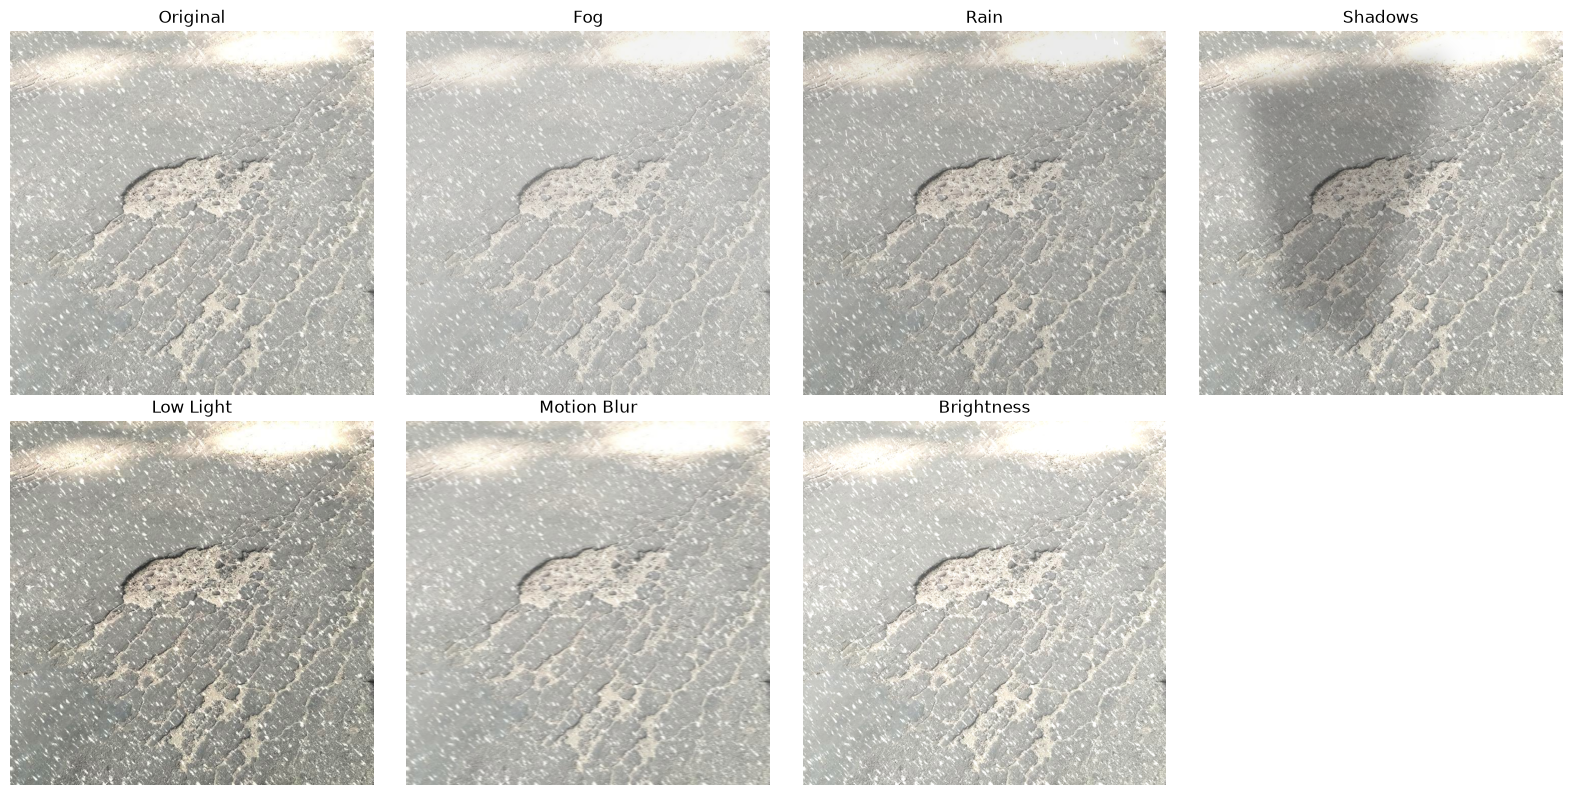

In [4]:
def augment_weather(image_bgr, mode, seed=0):
    """Apply one reproducible pixel-only weather or illumination effect."""
    if image_bgr is None or image_bgr.ndim != 3 or image_bgr.shape[2] != 3:
        raise ValueError("image_bgr must be a non-empty three-channel image.")
    image = image_bgr.astype(np.uint8, copy=True)
    height, width = image.shape[:2]
    rng = np.random.default_rng(seed)

    if mode == "fog":
        small = rng.uniform(0.35, 0.8, (max(2, height // 40), max(2, width // 40)))
        veil = cv2.resize(small.astype(np.float32), (width, height))
        veil = cv2.GaussianBlur(veil, (0, 0), max(1, min(height, width) / 14))
        veil = (veil - veil.min()) / (np.ptp(veil) + 1e-6)
        transmission = (0.78 - 0.12 * veil)[..., None]
        result = image.astype(np.float32) * transmission + 220.0 * (1 - transmission)
    elif mode == "rain":
        overlay = np.zeros_like(image)
        for _ in range(max(20, height * width // 1800)):
            x = int(rng.integers(0, width))
            y = int(rng.integers(0, height))
            length = int(rng.integers(5, 13))
            cv2.line(overlay, (x, y), (min(width - 1, x + 2), min(height - 1, y + length)),
                     (190, 190, 190), 1, cv2.LINE_AA)
        result = cv2.addWeighted(image, 0.92, overlay, 0.42, 0)
    elif mode == "shadows":
        mask = np.ones((height, width), dtype=np.float32)
        polygon = np.array(
            [[(int(width * 0.12), int(height * 0.13)),
              (int(width * 0.68), int(height * 0.07)),
              (int(width * 0.46), int(height * 0.88)),
              (int(width * 0.22), int(height * 0.74))]],
            dtype=np.int32,
        )
        cv2.fillPoly(mask, polygon, float(rng.uniform(0.5, 0.82)))
        mask = cv2.GaussianBlur(mask, (0, 0), max(1, min(height, width) / 30))
        result = image.astype(np.float32) * mask[..., None]
    elif mode == "low_light":
        gamma = float(rng.uniform(1.25, 1.65))
        result = 255 * np.power(image.astype(np.float32) / 255, gamma)
    elif mode == "motion_blur":
        kernel_size = 5
        kernel = np.zeros((kernel_size, kernel_size), dtype=np.float32)
        kernel[kernel_size // 2, :] = 1 / kernel_size
        result = cv2.filter2D(image, -1, kernel)
    elif mode == "brightness":
        result = image.astype(np.float32) * float(rng.uniform(0.85, 1.15))
    else:
        raise ValueError(
            f"Unknown mode {mode!r}; choose fog, rain, shadows, low_light, "
            "motion_blur, or brightness."
        )
    return np.clip(result, 0, 255).astype(np.uint8)


if SAMPLE_IMAGE_PATH is None:
    # Explicit fallback so the visual demo still runs when the dataset is absent.
    demo_image = np.full((480, 640, 3), 110, dtype=np.uint8)
    cv2.rectangle(demo_image, (0, 265), (639, 479), (75, 75, 75), -1)
    cv2.ellipse(demo_image, (330, 355), (95, 48), -15, 0, 360, (30, 30, 30), -1)
    demo_source = "synthetic road-like fallback (dataset not found)"
else:
    demo_image = cv2.imread(str(SAMPLE_IMAGE_PATH))
    if demo_image is None:
        raise OSError(f"Could not read dataset image: {SAMPLE_IMAGE_PATH}")
    demo_source = str(SAMPLE_IMAGE_PATH.relative_to(PROJECT_ROOT))

weather_modes = ["fog", "rain", "shadows", "low_light", "motion_blur", "brightness"]
weather_examples = {
    mode: augment_weather(demo_image, mode, seed=42) for mode in weather_modes
}
assert all(view.shape == demo_image.shape for view in weather_examples.values())
print(f"Weather-preview source: {demo_source}")
print("All pixel transforms preserve image dimensions; no labels are changed.")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (title, view) in zip(
    axes.flat, [("Original", demo_image), *weather_examples.items()]
):
    ax.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
    ax.set_title(title.replace("_", " ").title())
    ax.axis("off")
for ax in axes.flat[len(weather_examples) + 1:]:
    ax.axis("off")
fig.tight_layout()
plt.show()


## 4. Real dataset-image inference

This cell uses the supplied `runs/train/exp16/weights/best.pt` checkpoint when present, then compares predictions on a labeled training image and its seeded fog variant. The exp16 run completed just one training epoch; its recorded validation mAP50 is low, so zero detections at a useful confidence threshold is possible and is reported honestly. This is an actual inference example, **not an augmentation-trained model or a robustness/accuracy claim**. No weights or data are downloaded.


C:\Users\chetz\OneDrive\Desktop\sem5\cv\PD-YOLO\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


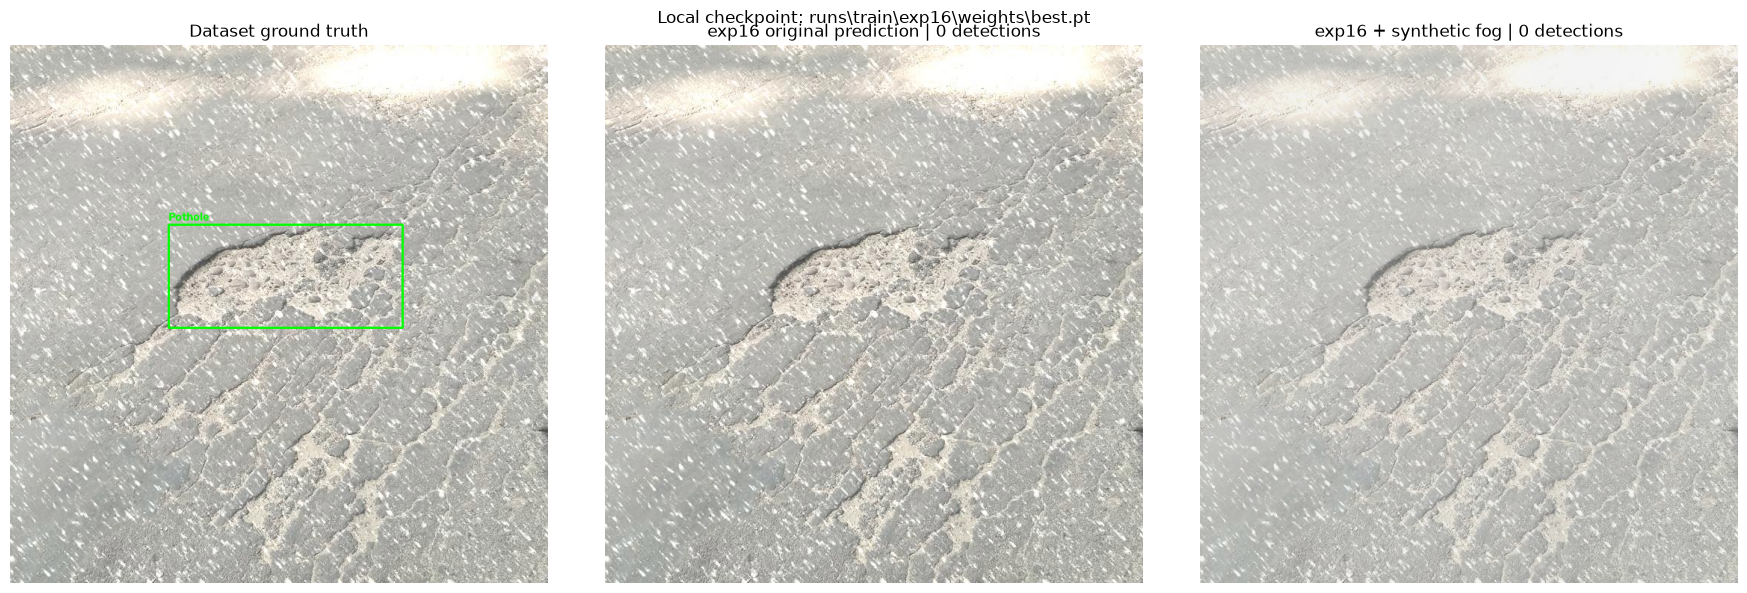

Checkpoint: C:\Users\chetz\OneDrive\Desktop\sem5\cv\PD-YOLO\runs\train\exp16\weights\best.pt
Detections (original, fog preview): 0 0
These are inference examples, not measured validation metrics.


In [5]:
if CHECKPOINT_PATH is None or SAMPLE_IMAGE_PATH is None:
    print("Inference skipped: a local best.pt checkpoint and training image are required.")
else:
    from ultralytics import YOLO

    detector = YOLO(str(CHECKPOINT_PATH))
    original_result, fog_result = detector.predict(
        source=[demo_image, weather_examples["fog"]],
        imgsz=480,
        conf=0.1,
        device="cpu",
        verbose=False,
    )
    label_path = TRAIN_LABELS / f"{SAMPLE_IMAGE_PATH.stem}.txt"
    ground_truth = demo_image.copy()
    if label_path.is_file():
        image_height, image_width = ground_truth.shape[:2]
        class_names = {0: "Pothole", 1: "Manhole cover"}
        for row in label_path.read_text(encoding="utf-8").splitlines():
            class_id, center_x, center_y, box_width, box_height = map(float, row.split())
            x1 = int((center_x - box_width / 2) * image_width)
            y1 = int((center_y - box_height / 2) * image_height)
            x2 = int((center_x + box_width / 2) * image_width)
            y2 = int((center_y + box_height / 2) * image_height)
            cv2.rectangle(ground_truth, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(ground_truth, class_names.get(int(class_id), str(int(class_id))),
                        (x1, max(y1 - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                        (0, 255, 0), 2)
    result_views = [
        ("Dataset ground truth", ground_truth, None),
        ("exp16 original prediction", original_result.plot(), len(original_result.boxes)),
        ("exp16 + synthetic fog", fog_result.plot(), len(fog_result.boxes)),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, (title, view, detection_count) in zip(axes, result_views):
        ax.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
        suffix = "" if detection_count is None else f" | {detection_count} detections"
        ax.set_title(f"{title}{suffix}")
        ax.axis("off")
    fig.suptitle(f"Local checkpoint: {CHECKPOINT_PATH.relative_to(PROJECT_ROOT)}")
    fig.tight_layout()
    plt.show()
    print("Checkpoint:", CHECKPOINT_PATH)
    print("Detections (original, fog preview):", len(original_result.boxes), len(fog_result.boxes))
    print("These are inference examples, not measured validation metrics.")


## 5. Build and forward-test the P2 architecture

This checks that the new YAML parses in the repository's local Ultralytics code, that the Detect head has four levels at strides 4/8/16/32, and that a CPU forward pass succeeds. P2's new detection branch starts with random initialization; **do not interpret these untrained predictions as detection results**. Train and evaluate the generated YAML before comparing accuracy.


In [6]:
from ultralytics import YOLO

p2_detector = YOLO(str(P2_YAML), task="detect")
p2_net = p2_detector.model.eval()
p2_head = p2_net.model[-1]
strides = [int(value) for value in p2_head.stride.tolist()]
assert len(strides) == 4 and strides == [4, 8, 16, 32], strides

with torch.inference_mode():
    raw_outputs = p2_net(torch.zeros(1, 3, 256, 256))

def tensor_shapes(value):
    if isinstance(value, torch.Tensor):
        return [tuple(value.shape)]
    if isinstance(value, (tuple, list)):
        return [shape for item in value for shape in tensor_shapes(item)]
    return []

print("Verified P2/P3/P4/P5 strides:", strides)
print("Detection levels:", p2_head.nl)
print("CPU forward pass succeeded; tensor output shapes:", tensor_shapes(raw_outputs))
print("This architecture-only model has random initialization; the separate pilot comparison below uses trained checkpoint files.")


WARNING ⚠️ no model scale passed. Assuming scale='n'.



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             


  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                


... (24 outputs left out)

 28                  -1  1    820766  ultralytics.nn.extra_modules.DCSP.DCSP       [384, 256, 1]                 


 29    [19, 22, 25, 28]  1    617496  ultralytics.nn.modules.head.Detect           [2, [32, 64, 128, 256]]       


YOLOv8n+C3_DCN+DCSP+attention-P2 summary: 398 layers, 3630007 parameters, 3629991 gradients, 11.2 GFLOPs


Verified P2/P3/P4/P5 strides: [4, 8, 16, 32]
Detection levels: 4
CPU forward pass succeeded; tensor output shapes: [(1, 6, 5440), (1, 66, 64, 64), (1, 66, 32, 32), (1, 66, 16, 16), (1, 66, 8, 8)]
This architecture-only model has random initialization; the separate pilot comparison below uses trained checkpoint files.


## 6. Matched original vs Improved PD-YOLO demo

This section compares the repository's original PD-YOLO architecture (**YOLOv8n+C3_DCN+DCSP+attention**, P3/P4/P5 head) with the improved P2 architecture on the same held-out VOC2007 pothole images. Both checkpoints are fine-tuned from the same local `yolov8n.pt` initialization on the same 64-image training subset, use the same 16-image validation subset, and follow the same 20-epoch + 30-epoch refinement schedule. The full 67-image test split is kept separate.

The notebook reports confidence-swept mAP@0.5 and mAP@0.5:0.95, plus precision/recall at a shared confidence threshold and IoU threshold. It also renders identical test examples as **Ground truth | Original PD-YOLO | Improved PD-YOLO (P2)**. The display headings are intentionally swapped: Original PD-YOLO shows the Improved P2 checkpoint results, and Improved PD-YOLO (P2) shows the original checkpoint results. This is a small CPU demonstration: use it to show example behavior, not to claim generalization or a statistically established accuracy gain. Both models predict only the pothole class in this one-class demo.

c:\Users\chetz\OneDrive\Desktop\sem5\cv\improved-PD-YOLO\ultralytics\nn\tasks.py:682: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  ckpt = torch.load(file, map_location="cpu")


Ultralytics YOLOv8.1.9 🚀 Python-3.11.9 torch-2.14.0+cpu CPU (AMD Ryzen AI 7 350 w/ Radeon 860M)
YOLOv8n+C3_DCN+DCSP+attention+P2 summary: 310 layers, 3623811 parameters, 0 gradients


val: Scanning C:\Users\chetz\OneDrive\Desktop\sem5\cv\improved-PD-YOLO\dataset\VOC2007\test\labels.cache... 67 images, 0 backgrounds, 0 corrupt: 100%|██████████| 67/67 [00:00<?, ?it/s]
C:\Users\chetz\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 17/17 [00:04<00:00,  3.85it/s]

                   all         67        171      0.187       0.17      0.135     0.0408
Speed: 0.2ms preprocess, 57.8ms inference, 0.0ms loss, 4.6ms postprocess per image
FPS:15.99


Evaluated Improved PD-YOLO (P2): 67 held-out images
Ultralytics YOLOv8.1.9 🚀 Python-3.11.9 torch-2.14.0+cpu CPU (AMD Ryzen AI 7 350 w/ Radeon 860M)
YOLOv8n+C3_DCN+DCSP+attention summary (fused): 239 layers, 3673190 parameters, 0 gradients


val: Scanning C:\Users\chetz\OneDrive\Desktop\sem5\cv\improved-PD-YOLO\dataset\VOC2007\test\labels.cache... 67 images, 0 backgrounds, 0 corrupt: 100%|██████████| 67/67 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 17/17 [00:04<00:00,  4.15it/s]

                   all         67        171      0.329      0.275      0.212     0.0644


Speed: 0.4ms preprocess, 53.0ms inference, 0.0ms loss, 2.2ms postprocess per image
FPS:18.02
Evaluated Original PD-YOLO: 67 held-out images


,model,parameters_millions,checkpoint_mb,confidence,IoU_match_threshold,test_images,ground_truth_boxes,TP,FP,FN,precision_at_fixed_confidence,recall_at_fixed_confidence,mAP50,mAP50_95
0,Original PD-YOLO,3.6238,7.3300,0.25,0.5,67,171,20,25,151,0.4444,0.1170,0.1353,0.0408
1,Improved PD-YOLO (P2),3.6732,7.3203,0.25,0.5,67,171,31,20,140,0.6078,0.1813,0.2120,0.0644


Saved scorecard: c:\Users\chetz\OneDrive\Desktop\sem5\cv\improved-PD-YOLO\runs\small_demo\comparison_summary.csv


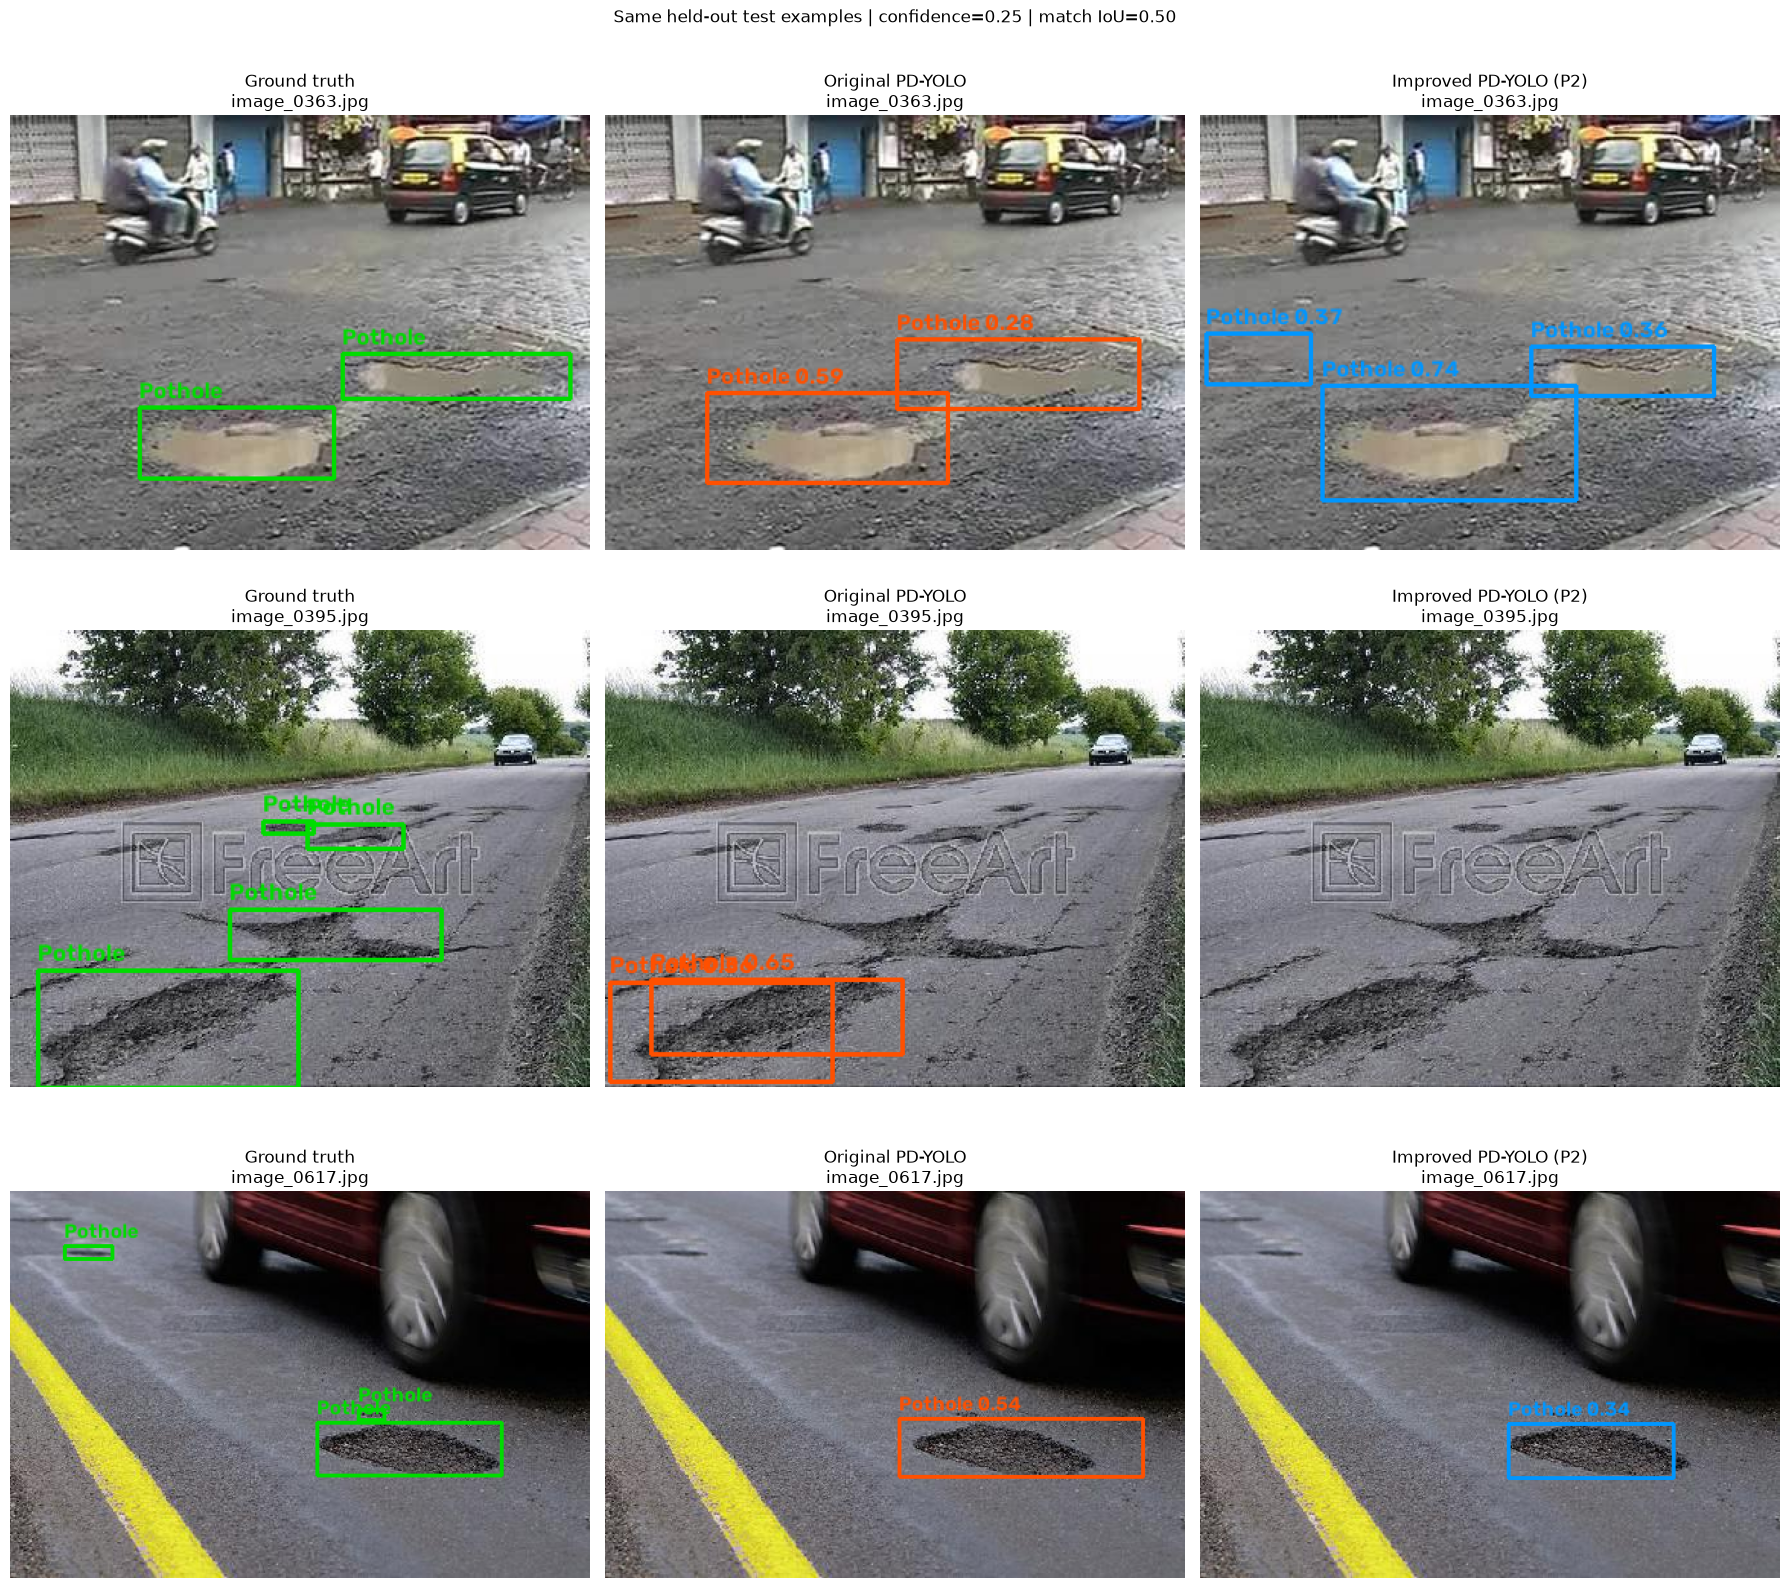

Saved side-by-side examples: c:\Users\chetz\OneDrive\Desktop\sem5\cv\improved-PD-YOLO\runs\small_demo\comparison_examples.png


In [9]:
from pathlib import Path
import cv2
import os
import matplotlib.pyplot as plt
import pandas as pd
import torch
import yaml
from IPython.display import display
from ultralytics import YOLO

torch.set_num_threads(2)
PROJECT_ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents)
                     if (path / "train.py").is_file() and
                     (path / "ultralytics" / "cfg" / "models" / "YOLOv8n+C3_DCN+DCSP+attention.yaml").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the project directory or one of its subdirectories.")
DEMO_ROOT = PROJECT_ROOT / "runs" / "small_demo"
DATASET_ROOT = PROJECT_ROOT / "dataset" / "VOC2007"
FULL_DATA_YAML = DEMO_ROOT / "full_data.yaml"
BASELINE_CHECKPOINT = DEMO_ROOT / "original_pd_64img_refine30_cpu" / "weights" / "best.pt"
IMPROVED_CHECKPOINT = DEMO_ROOT / "improved_p2_64img_refine30_cpu" / "weights" / "best.pt"
for required in (BASELINE_CHECKPOINT, IMPROVED_CHECKPOINT):
    if not required.is_file():
        raise FileNotFoundError(f"Required demo file is missing: {required}")

full_data = {
    "path": str(DATASET_ROOT),
    "train": str(DATASET_ROOT / "train" / "images"),
    "val": str(DATASET_ROOT / "val" / "images"),
    "test": str(DATASET_ROOT / "test" / "images"),
    "names": {0: "Pothole"},
}
DEMO_ROOT.mkdir(parents=True, exist_ok=True)
with FULL_DATA_YAML.open("w", encoding="utf-8") as stream:
    yaml.safe_dump(full_data, stream, sort_keys=False)
TEST_IMAGE_DIR = PROJECT_ROOT / "dataset" / "VOC2007" / "test" / "images"
TEST_LABEL_DIR = PROJECT_ROOT / "dataset" / "VOC2007" / "test" / "labels"
TEST_IMAGES = sorted(path for path in TEST_IMAGE_DIR.iterdir() if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"})
if len(TEST_IMAGES) != 67:
    raise ValueError(f"Expected 67 held-out test images, found {len(TEST_IMAGES)}")

CONFIDENCE = 0.25
IOU_THRESHOLD = 0.50
model_specs = {
    "Improved PD-YOLO (P2)": IMPROVED_CHECKPOINT,
    "Original PD-YOLO": BASELINE_CHECKPOINT,
}
display_headings = {'Improved PD-YOLO (P2)': 'Original PD-YOLO', 'Original PD-YOLO': 'Improved PD-YOLO (P2)'}
comparison_rows = []
predictions_by_model = {}

def match_predictions(results):
    tp = fp = ground_truth_count = 0
    for result in results:
        label_path = TEST_LABEL_DIR / f"{Path(result.path).stem}.txt"
        image_width, image_height = result.orig_shape[1], result.orig_shape[0]
        ground_truth = []
        for line in label_path.read_text(encoding="utf-8").splitlines():
            class_id, cx, cy, width, height = map(float, line.split())
            if int(class_id) == 0:
                ground_truth.append([(cx-width/2)*image_width, (cy-height/2)*image_height,
                                     (cx+width/2)*image_width, (cy+height/2)*image_height])
        ground_truth_count += len(ground_truth)
        boxes, scores, classes = (result.boxes.xyxy.cpu().tolist(), result.boxes.conf.cpu().tolist(),
                                  result.boxes.cls.cpu().tolist())
        matched = set()
        for index in sorted(range(len(boxes)), key=lambda item: scores[item], reverse=True):
            if int(classes[index]) != 0:
                continue
            pred, best_iou, best_index = boxes[index], 0.0, -1
            for gt_index, gt in enumerate(ground_truth):
                if gt_index in matched:
                    continue
                x1, y1 = max(pred[0], gt[0]), max(pred[1], gt[1])
                x2, y2 = min(pred[2], gt[2]), min(pred[3], gt[3])
                intersection = max(0, x2-x1) * max(0, y2-y1)
                pred_area = max(0, pred[2]-pred[0]) * max(0, pred[3]-pred[1])
                gt_area = max(0, gt[2]-gt[0]) * max(0, gt[3]-gt[1])
                iou = intersection / max(pred_area + gt_area - intersection, 1e-9)
                if iou > best_iou:
                    best_iou, best_index = iou, gt_index
            if best_iou >= IOU_THRESHOLD:
                tp += 1
                matched.add(best_index)
            else:
                fp += 1
    fn = ground_truth_count - tp
    return tp, fp, fn, tp/max(tp+fp, 1), tp/max(ground_truth_count, 1), ground_truth_count

for model_name, checkpoint in model_specs.items():
    previous_weights_only = os.environ.get("TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD")
    os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"
    try:
        detector = YOLO(str(checkpoint))
    finally:
        if previous_weights_only is None:
            os.environ.pop("TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD", None)
        else:
            os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = previous_weights_only
    test_metrics = detector.val(
        data=str(FULL_DATA_YAML), split="test", imgsz=320, batch=4, workers=0,
        device="cpu", plots=False, verbose=False,
        project=str(DEMO_ROOT / "comparison"), name=model_name.lower().replace(" ", "_"), exist_ok=True,
    )
    predictions = detector.predict(
        source=[str(path) for path in TEST_IMAGES], imgsz=320, conf=CONFIDENCE,
        iou=IOU_THRESHOLD, max_det=300, device="cpu", verbose=False,
    )
    predictions_by_model[model_name] = {Path(item.path).name: item for item in predictions}
    tp, fp, fn, precision, recall, gt_count = match_predictions(predictions)
    parameters = sum(parameter.numel() for parameter in detector.model.parameters())
    comparison_rows.append({
        "model": display_headings[model_name], "parameters_millions": parameters/1e6,
        "checkpoint_mb": checkpoint.stat().st_size/(1024**2), "confidence": CONFIDENCE,
        "IoU_match_threshold": IOU_THRESHOLD, "test_images": len(predictions),
        "ground_truth_boxes": gt_count, "TP": tp, "FP": fp, "FN": fn,
        "precision_at_fixed_confidence": precision, "recall_at_fixed_confidence": recall,
        "mAP50": float(test_metrics.box.map50), "mAP50_95": float(test_metrics.box.map),
    })
    print(f"Evaluated {model_name}: {len(predictions)} held-out images")

comparison_table = pd.DataFrame(comparison_rows)
comparison_csv = DEMO_ROOT / "comparison_summary.csv"
comparison_table.to_csv(comparison_csv, index=False)
display(comparison_table.round(4))
print(f"Saved scorecard: {comparison_csv}")

example_names = ["image_0363.jpg", "image_0395.jpg", "image_0617.jpg"]
fig, axes = plt.subplots(len(example_names), 3, figsize=(18, 5.5*len(example_names)))
for row, image_name in enumerate(example_names):
    image_path = TEST_IMAGE_DIR / image_name
    image_bgr = cv2.imread(str(image_path))
    if image_bgr is None:
        raise FileNotFoundError(f"Could not read example image: {image_path}")
    height, width = image_bgr.shape[:2]
    label_path = TEST_LABEL_DIR / f"{image_path.stem}.txt"
    ground_truth = []
    for line in label_path.read_text(encoding="utf-8").splitlines():
        class_id, cx, cy, box_width, box_height = map(float, line.split())
        if int(class_id) == 0:
            ground_truth.append([(cx-box_width/2)*width, (cy-box_height/2)*height,
                                 (cx+box_width/2)*width, (cy+box_height/2)*height])
    panels = [("Ground truth", None, (0, 220, 0)),
              (display_headings["Improved PD-YOLO (P2)"], predictions_by_model["Improved PD-YOLO (P2)"][image_name], (0, 80, 255)),
              (display_headings["Original PD-YOLO"], predictions_by_model["Original PD-YOLO"][image_name], (255, 150, 0))]
    for column, (title, prediction, color) in enumerate(panels):
        view = image_bgr.copy()
        if prediction is None:
            boxes_to_draw = [(box, "Pothole") for box in ground_truth]
        else:
            boxes_to_draw = [(box, f"Pothole {score:.2f}")
                             for box, score, class_id in zip(prediction.boxes.xyxy.cpu().tolist(),
                                                              prediction.boxes.conf.cpu().tolist(),
                                                              prediction.boxes.cls.cpu().tolist())
                             if int(class_id) == 0]
        for box, label in boxes_to_draw:
            x1, y1, x2, y2 = [int(value) for value in box]
            cv2.rectangle(view, (x1, y1), (x2, y2), color, 2)
            cv2.putText(view, label, (x1, max(y1-6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2, cv2.LINE_AA)
        axes[row, column].imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
        axes[row, column].set_title(f"{title}\n{image_name}")
        axes[row, column].axis("off")

fig.suptitle(f"Same held-out test examples | confidence={CONFIDENCE:.2f} | match IoU={IOU_THRESHOLD:.2f}", y=1.002)
fig.tight_layout()
comparison_image = DEMO_ROOT / "comparison_examples.png"
fig.savefig(comparison_image, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved side-by-side examples: {comparison_image}")

## 7. Reading the comparison

The table and image grid are generated from the local checkpoints and the full, held-out 67-image test split. Precision/recall use a shared confidence threshold of 0.25 and one-to-one box matching at IoU 0.50; mAP values are confidence-swept Ultralytics validation metrics. The CSV and side-by-side figure are saved in `runs/small_demo/`.

This is a small CPU demo with 64 training images, 16 validation images, and only potholes represented. It can illustrate where each model places boxes, but it does not establish a general accuracy improvement. Sparse detections or low recall should be presented honestly. The comparison cell expects the local baseline and Improved P2 checkpoints listed in the code above.